# Spec-S5 BGS SNR & Redshift Recovery Demo

This notebook demonstrates the BGS (Bright Galaxy Survey) ETC and
redshift-recovery model added in `spec5.instrument.bgs_etc` and
`spec5.instrument.galaxy_photometry`:

1. `fiber_capture_fraction` — how much of an extended galaxy's light falls
   within the fiber, as a function of half-light radius and fiber size
2. `compute_bgs_snr` — r-arm continuum SNR for Spec-S5 and DESI
3. `compute_redshift_success` — binary redshift-success probability,
   calibrated against the public DESI DR1 BGS_BRIGHT catalog
4. A mock BGS galaxy catalog, observed with `observe_bgs_with_spec5` /
   `observe_bgs_with_desi`

Unlike the stellar model, BGS targets are **extended sources** and redshift
recovery is modeled as a **binary** success/failure outcome (DESI's own
ZWARN/DELTACHI2 framework has no continuous redshift-error model). See
`docs/bgs_plan.md` and `docs/bgs_path_b_results.md` for the full research
behind these choices.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt

from spec5.instrument.bgs_etc import compute_bgs_snr, compute_redshift_success
from spec5.instrument.galaxy_photometry import fiber_capture_fraction
from spec5.instrument.mock_observations import observe_bgs_with_desi, observe_bgs_with_spec5

## 1. Fiber aperture loss for extended sources

Only part of a galaxy's light falls within the fiber. `fiber_capture_fraction`
models this with a Sersic light profile (default: exponential disk, `n=1`,
typical of star-forming BGS targets) and the standard curve-of-growth
formula. Spec-S5's baseline 107 µm fiber (1.02") is smaller than DESI's
(1.51"), so it captures a smaller fraction of an extended galaxy's flux —
this is the key new physical effect relative to the point-source stellar
model.

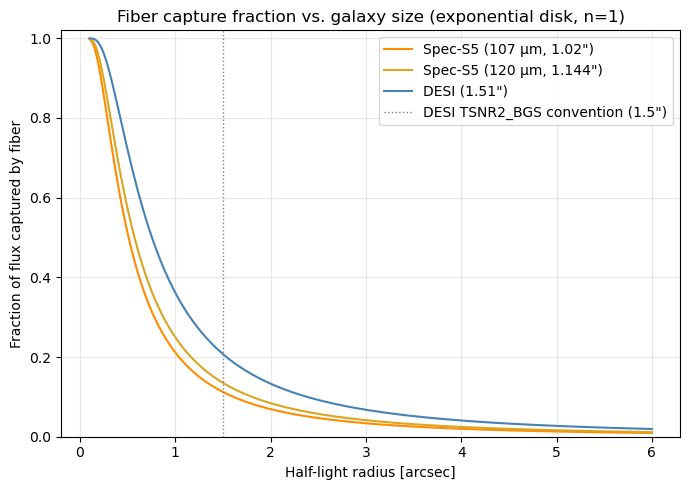

In [2]:
half_light_radii = np.linspace(0.1, 6.0, 200)  # arcsec

fig, ax = plt.subplots(figsize=(7, 5))
for fiber_diameter, label, color in [
    (1.02,  'Spec-S5 (107 µm, 1.02")', 'darkorange'),
    (1.144, 'Spec-S5 (120 µm, 1.144")', 'goldenrod'),
    (1.51,  'DESI (1.51")',             'steelblue'),
]:
    frac = fiber_capture_fraction(half_light_radii, fiber_diameter, sersic_n=1.0)
    ax.plot(half_light_radii, frac, '-', color=color, label=label)

ax.axvline(1.5, color='gray', ls=':', lw=1, label='DESI TSNR2_BGS convention (1.5")')
ax.set(xlabel='Half-light radius [arcsec]', ylabel='Fraction of flux captured by fiber',
       title='Fiber capture fraction vs. galaxy size (exponential disk, n=1)',
       ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. r-arm continuum SNR: `compute_bgs_snr`

`compute_bgs_snr` takes a galaxy's r-band magnitude in DESI's reference
1.51" fiber-flux convention (the same convention as the Legacy Survey
`FIBERFLUX_R` quantity) and a half-light radius, and returns the continuum
SNR in DESI's r-arm (5760–7620 Å) for both Spec-S5 and DESI.

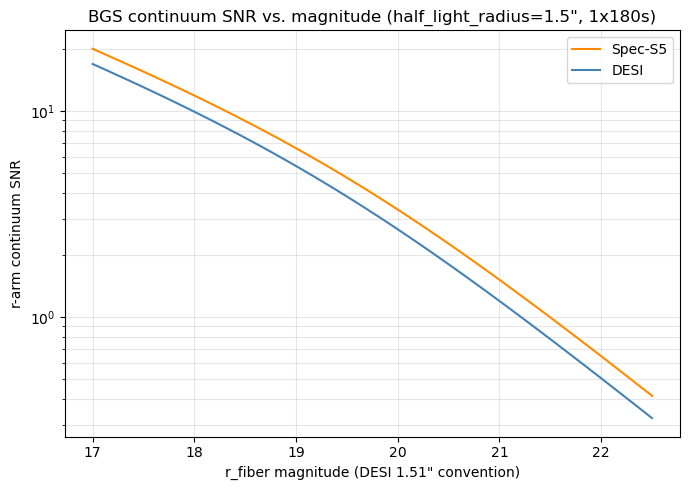

Fiber capture fraction at r_half=1.5": Spec-S5=0.112  DESI=0.207
Spec-S5/DESI SNR ratio (same r_fiber_mag): 1.241


In [3]:
mags = np.linspace(17.0, 22.5, 60)
half_light_radius = 1.5  # arcsec, DESI's TSNR2_BGS convention

snr = compute_bgs_snr(mags, nexp=1, texp=180.0, half_light_radius=half_light_radius)

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(mags, snr['snr_r_s5'], '-', color='darkorange', label='Spec-S5')
ax.semilogy(mags, snr['snr_r_d'],  '-', color='steelblue',  label='DESI')
ax.set(xlabel='r_fiber magnitude (DESI 1.51" convention)', ylabel='r-arm continuum SNR',
       title=f'BGS continuum SNR vs. magnitude (half_light_radius={half_light_radius}", 1x180s)')
ax.legend()
ax.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

print(f"Fiber capture fraction at r_half={half_light_radius}\": "
      f"Spec-S5={snr['capture_frac_s5'][0]:.3f}  DESI={snr['capture_frac_d'][0]:.3f}")
print(f"Spec-S5/DESI SNR ratio (same r_fiber_mag): "
      f"{np.median(snr['snr_r_s5'] / snr['snr_r_d']):.3f}")

### Per-wavelength SNR for a single example galaxy

The same per-Å SNR arrays used for the r-arm median above, shown across
the full throughput curve (as in the stellar `plot_snr_comparison`).

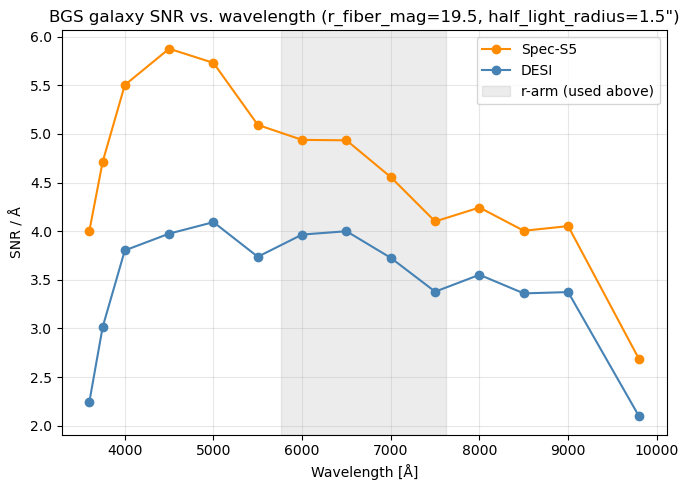

In [4]:
example = compute_bgs_snr(19.5, nexp=1, texp=180.0, half_light_radius=1.5)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(example['lam_t'], example['snr_s5_t'], 'o-', color='darkorange', label='Spec-S5')
ax.plot(example['lam_t'], example['snr_d_t'],  'o-', color='steelblue',  label='DESI')
ax.axvspan(5760, 7620, color='gray', alpha=0.15, label='r-arm (used above)')
ax.set(xlabel='Wavelength [Å]', ylabel='SNR / Å',
       title='BGS galaxy SNR vs. wavelength (r_fiber_mag=19.5, half_light_radius=1.5")')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Redshift-success probability: `compute_redshift_success`

The DESI curve (`instrument='desi'`) is the direct empirical calibration
from the DR1 BGS_BRIGHT catalog (points overlaid below, from
`spec5/instrument/data/bgs_redshift_success_bright.csv` — see
`docs/bgs_path_b_results.md`). The Spec-S5 curve (`instrument='spec5'`)
translates the input magnitude through the actual Spec-S5/DESI SNR ratio
computed above before evaluating the same DESI-calibrated relation.

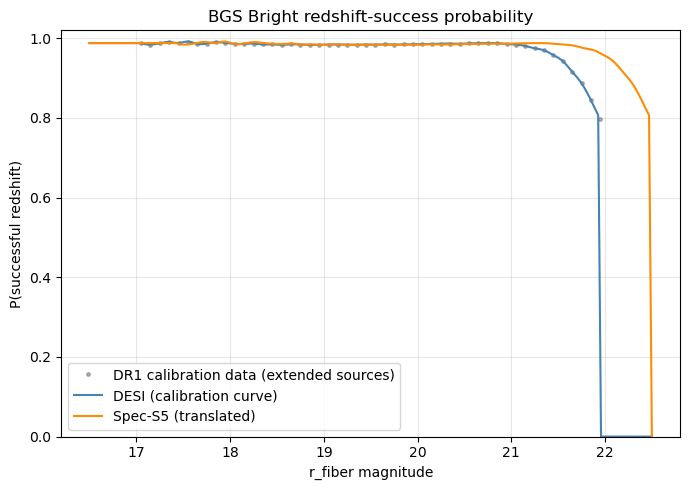

In [5]:
calib = np.loadtxt('../spec5/instrument/data/bgs_redshift_success_bright.csv',
                   delimiter=',', comments='#')
calib_mag, calib_rate = calib[:, 0], calib[:, 1]

mags_fine = np.linspace(16.5, 22.5, 200)
p_desi  = compute_redshift_success(mags_fine, instrument='desi')
p_spec5 = compute_redshift_success(mags_fine, instrument='spec5', half_light_radius=1.5)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(calib_mag, calib_rate, '.', color='gray', ms=5, alpha=0.6,
        label='DR1 calibration data (extended sources)')
ax.plot(mags_fine, p_desi,  '-', color='steelblue',  label='DESI (calibration curve)')
ax.plot(mags_fine, p_spec5, '-', color='darkorange', label='Spec-S5 (translated)')
ax.set(xlabel='r_fiber magnitude', ylabel='P(successful redshift)',
       title='BGS Bright redshift-success probability', ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Mock BGS galaxy catalog

We draw a toy BGS Bright-like catalog: magnitudes roughly following the
flux-limited r<19.5 selection with a faint tail, half-light radii
log-normally distributed around 1.5" (DESI's TSNR2_BGS convention), and
redshifts uniform over 0.05–0.4 (the BGS redshift range).

In [6]:
rng = np.random.default_rng(42)
n = 2000

# Magnitudes: concentrated near the bright/nominal regime with a faint tail
# reaching into the BGS Faint-like range, to show success rate varying.
r_fiber_mag = rng.normal(20.0, 1.2, n)
r_fiber_mag = np.clip(r_fiber_mag, 16.5, 22.5)

# Half-light radii: log-normal around 1.5"
half_light_radius = rng.lognormal(mean=np.log(1.5), sigma=0.4, size=n)

# Redshifts: uniform over the BGS range
redshift = rng.uniform(0.05, 0.4, n)

dtype = [('r_fiber_mag', 'f8'), ('half_light_radius', 'f8'), ('redshift', 'f8')]
galaxies = np.empty(n, dtype=dtype)
galaxies['r_fiber_mag'] = r_fiber_mag
galaxies['half_light_radius'] = half_light_radius
galaxies['redshift'] = redshift

print(f'r_fiber_mag:       {r_fiber_mag.min():.2f} - {r_fiber_mag.max():.2f}')
print(f'half_light_radius: {half_light_radius.min():.2f} - {half_light_radius.max():.2f} arcsec')
print(f'redshift:          {redshift.min():.2f} - {redshift.max():.2f}')

r_fiber_mag:       16.50 - 22.50
half_light_radius: 0.44 - 5.16 arcsec
redshift:          0.05 - 0.40


## 5. Apply `observe_bgs_with_spec5` / `observe_bgs_with_desi`

Each call draws a per-galaxy Bernoulli redshift-success outcome from
`compute_redshift_success`.

In [7]:
mock_spec5 = observe_bgs_with_spec5(galaxies, seed=1)
mock_desi  = observe_bgs_with_desi(galaxies, seed=1)

print(f"{'':20s} {'Spec-S5':>12s} {'DESI':>12s}")
print(f"{'overall success':20s} {mock_spec5['success'].mean():>12.4f} {mock_desi['success'].mean():>12.4f}")
print(f"{'n successes':20s} {mock_spec5['success'].sum():>12d} {mock_desi['success'].sum():>12d}")

                          Spec-S5         DESI
overall success            0.9750       0.9380
n successes                  1950         1876


## 6. Comparison plots

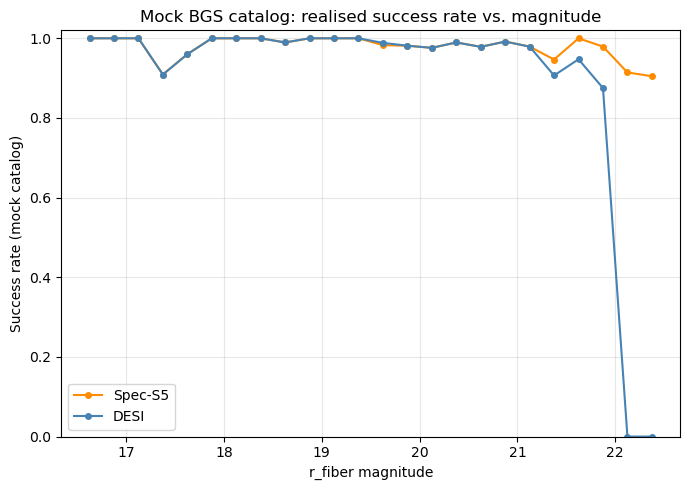

In [8]:
mag_bins = np.linspace(16.5, 22.5, 25)
bin_centers = 0.5 * (mag_bins[:-1] + mag_bins[1:])

fig, ax = plt.subplots(figsize=(7, 5))
for mock, label, color in [(mock_spec5, 'Spec-S5', 'darkorange'), (mock_desi, 'DESI', 'steelblue')]:
    rates = []
    for lo, hi in zip(mag_bins[:-1], mag_bins[1:]):
        sel = (galaxies['r_fiber_mag'] >= lo) & (galaxies['r_fiber_mag'] < hi)
        rates.append(mock['success'][sel].mean() if sel.any() else np.nan)
    ax.plot(bin_centers, rates, 'o-', color=color, label=label, ms=4)

ax.set(xlabel='r_fiber magnitude', ylabel='Success rate (mock catalog)',
       title='Mock BGS catalog: realised success rate vs. magnitude', ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

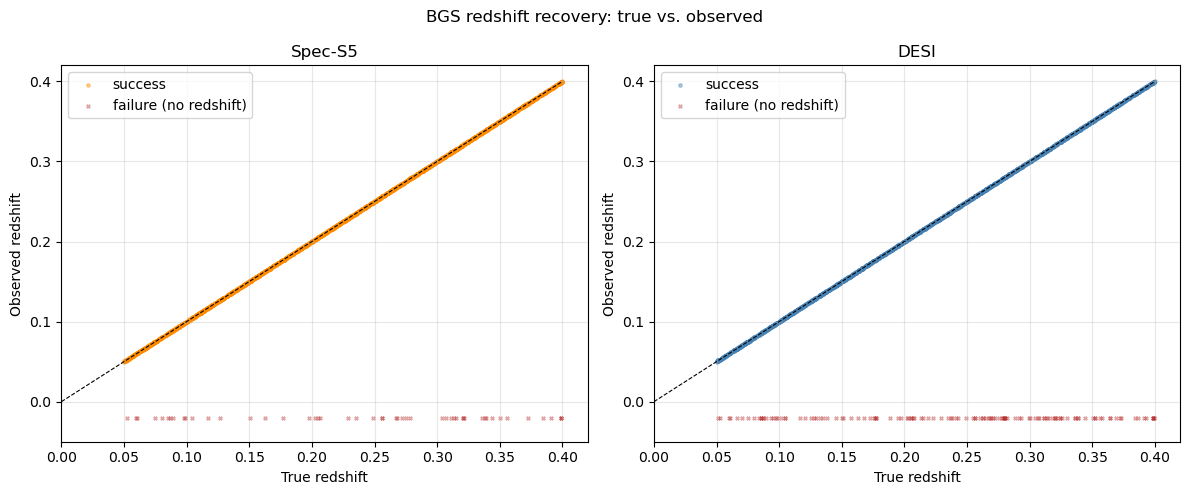

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

for ax, mock, label, color in [
    (axs[0], mock_spec5, 'Spec-S5', 'darkorange'),
    (axs[1], mock_desi,  'DESI',    'steelblue'),
]:
    success = mock['success']
    ax.scatter(galaxies['redshift'][success], mock['redshift_obs'][success],
               s=6, alpha=0.4, color=color, label='success')
    ax.scatter(galaxies['redshift'][~success], np.zeros(np.sum(~success)) - 0.02,
               s=6, alpha=0.4, color='firebrick', marker='x', label='failure (no redshift)')
    ax.plot([0, 0.4], [0, 0.4], 'k--', lw=0.8)
    ax.set(xlabel='True redshift', ylabel='Observed redshift', title=label,
           xlim=(0, 0.42), ylim=(-0.05, 0.42))
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

plt.suptitle('BGS redshift recovery: true vs. observed')
plt.tight_layout()
plt.show()

## Summary

- Spec-S5's larger (6m) mirror more than compensates for its smaller
  fiber's extra aperture loss on extended BGS-like galaxies, giving a
  modestly higher predicted redshift-success rate than DESI at the same
  apparent magnitude — most visible at the faint end, where DESI's success
  rate falls off more steeply.
- Both predictions are binary (Bernoulli) redshift-success models, not
  continuous redshift-error models, matching DESI's own ZWARN/Δχ² framework.
- Only **BGS Bright** is currently calibrated; see `docs/bgs_plan.md` for
  the BGS Faint follow-up and other open items.